In [1]:
import pandas as pd
import matplotlib as plt
import sklearn
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('data/combined_transfers.csv')


print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (177412, 13)


,club_name,player_name,age,position,club_involved_name,fee,transfer_movement,transfer_period,fee_cleaned,league_name,year,season,country
0,1.FC Saarbrücken,Thomas Stratos,25.0,Defensive Midfield,Hamburger SV,€150Th.,in,Summer,0.15,1 Bundesliga,1992,1992/1993,Germany
1,1.FC Saarbrücken,Matthias Lust,22.0,Left Midfield,Waldh. Mannheim,free transfer,in,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
2,1.FC Saarbrücken,Henning Bürger,22.0,Left Midfield,FC Schalke 04,free transfer,in,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
3,1.FC Saarbrücken,Michael Hennig,20.0,midfield,FC Berlin,free transfer,in,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
4,1.FC Saarbrücken,Malik Badji,24.0,defence,CS Sedan,?,in,Summer,NaN,1 Bundesliga,1992,1992/1993,Germany


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177412 entries, 0 to 177411
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   club_name           177412 non-null  object 
 1   player_name         177412 non-null  object 
 2   age                 177342 non-null  float64
 3   position            177412 non-null  object 
 4   club_involved_name  177412 non-null  object 
 5   fee                 177299 non-null  object 
 6   transfer_movement   177412 non-null  object 
 7   transfer_period     177412 non-null  object 
 8   fee_cleaned         66564 non-null   float64
 9   league_name         177412 non-null  object 
 10  year                177412 non-null  int64  
 11  season              177412 non-null  object 
 12  country             177412 non-null  object 
dtypes: float64(2), int64(1), object(10)
memory usage: 17.6+ MB


club_name: Klubben som är i fokus för transaktionen
club_involved_name: Den andra klubben som är involverad i transaktionen
transfer_movement: Riktning för club_name - "in" eller "out"
För transfers "in":

Spelare transfereras TILL club_name FRÅN club_involved_name
För transfers "out":

Spelare transfereras FRÅN club_name TILL club_involved_name

In [4]:

df_transfers = df.copy()


df_transfers['to_club'] = df_transfers.apply(lambda row: row['club_name'] if row['transfer_movement'] == 'in' 
                        else row['club_involved_name'], axis=1)
df_transfers['from_club'] = df_transfers.apply(lambda row: row['club_involved_name'] if row['transfer_movement'] == 'in' 
                          else row['club_name'], axis=1)


df_transfers = df_transfers.drop(['club_name', 'club_involved_name', 'transfer_movement'], axis=1)


cols = ['to_club', 'from_club'] + [col for col in df_transfers.columns if col not in ['to_club', 'from_club']]
df_transfers = df_transfers[cols]

print(f"Nytt dataset (df_transfers) shape: {df_transfers.shape}")
print(f"Original dataset (df) shape: {df.shape}")
df_transfers.head()

Nytt dataset (df_transfers) shape: (177412, 12)
Original dataset (df) shape: (177412, 13)


,to_club,from_club,player_name,age,position,fee,transfer_period,fee_cleaned,league_name,year,season,country
0,1.FC Saarbrücken,Hamburger SV,Thomas Stratos,25.0,Defensive Midfield,€150Th.,Summer,0.15,1 Bundesliga,1992,1992/1993,Germany
1,1.FC Saarbrücken,Waldh. Mannheim,Matthias Lust,22.0,Left Midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
2,1.FC Saarbrücken,FC Schalke 04,Henning Bürger,22.0,Left Midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
3,1.FC Saarbrücken,FC Berlin,Michael Hennig,20.0,midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
4,1.FC Saarbrücken,CS Sedan,Malik Badji,24.0,defence,?,Summer,NaN,1 Bundesliga,1992,1992/1993,Germany


jag har justerat strukturen så att

to_club: Klubben spelaren transfereras TILL (alltid destinationsklubben)
from_club: Klubben spelaren transfereras FRÅN (alltid ursprungsklubben)
transfer_movement: Borttagen helt

In [5]:
print(f"Antal transferer med 0.00 eller NaN: {((df_transfers['fee_cleaned'] == 0.00) | (df_transfers['fee_cleaned'].isnull())).sum()}")
print(f"Andel av totala transferer: {((df_transfers['fee_cleaned'] == 0.00) | (df_transfers['fee_cleaned'].isnull())).sum()/len(df_transfers)*100:.1f}%")


Antal transferer med 0.00 eller NaN: 144443
Andel av totala transferer: 81.4%


In [6]:
def convert_fee_to_float(fee_str):
    """Konverterar fee-strängar som €150Th. till 150000.0 och €1.25m till 1250000.0"""
    if pd.isna(fee_str) or fee_str in ['free transfer', '?', '-', 'loan transfer'] or 'End of loan' in str(fee_str) or 'loan' in str(fee_str).lower():
        return fee_str  # Behåll som de är
    
    fee_str = str(fee_str).replace('€', '') 
    
    if fee_str.endswith('Th.'):
        number_part = fee_str[:-3] 
        try:
            number = float(number_part)
            return number * 1000
        except:
            return fee_str
    elif fee_str.endswith('m'):
        number_part = fee_str[:-1] 
        try:
            number = float(number_part)
            return number * 1000000
        except:
            return fee_str
    else:
        return fee_str  # Lämna alla andra värden som de är

In [7]:

print("Exempel på fee-värden före konvertering:")
print(df_transfers['fee'].dropna().head(10))


df_transfers['fee'] = df_transfers['fee'].apply(convert_fee_to_float)


print("\nExempel på fee-värden efter konvertering:")
print(df_transfers['fee'].dropna().head(10))



large_values = df_transfers[df_transfers['fee'].apply(lambda x: isinstance(x, (int, float)) and x >= 1000000)]
if len(large_values) > 0:
    print(f"\nExempel på stora värden (>=1M):")
    print(large_values[['player_name', 'fee', 'to_club', 'from_club']].head(10))
else:
    print("\nInga stora värden (>=1M) hittades")

Exempel på fee-värden före konvertering:
0          €150Th.
1    free transfer
2    free transfer
3    free transfer
4                ?
5                ?
6                ?
7                ?
8                ?
9                ?
Name: fee, dtype: object

Exempel på fee-värden efter konvertering:
0         150000.0
1    free transfer
2    free transfer
3    free transfer
4                ?
5                ?
6                ?
7                ?
8                ?
9                ?
Name: fee, dtype: object

Exempel på stora värden (>=1M):
              player_name        fee           to_club        from_club
49         Andreas Herzog  1500000.0  SV Werder Bremen     Rapid Vienna
50   Dietmar Beiersdorfer  1000000.0  SV Werder Bremen     Hamburger SV
67            André Golke  1250000.0     VfB Stuttgart   1.FC Nuremberg
70        Matthias Sammer  6000000.0             Inter    VfB Stuttgart
84          Mehmet Scholl  2500000.0     Bayern Munich    Karlsruher SC
106  Dietmar Beiersdo

In [8]:
df_transfers.head()

,to_club,from_club,player_name,age,position,fee,transfer_period,fee_cleaned,league_name,year,season,country
0,1.FC Saarbrücken,Hamburger SV,Thomas Stratos,25.0,Defensive Midfield,150000.0,Summer,0.15,1 Bundesliga,1992,1992/1993,Germany
1,1.FC Saarbrücken,Waldh. Mannheim,Matthias Lust,22.0,Left Midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
2,1.FC Saarbrücken,FC Schalke 04,Henning Bürger,22.0,Left Midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
3,1.FC Saarbrücken,FC Berlin,Michael Hennig,20.0,midfield,free transfer,Summer,0.00,1 Bundesliga,1992,1992/1993,Germany
4,1.FC Saarbrücken,CS Sedan,Malik Badji,24.0,defence,?,Summer,NaN,1 Bundesliga,1992,1992/1993,Germany


In [9]:
df_transfers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177412 entries, 0 to 177411
Data columns (total 12 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   to_club          177412 non-null  object 
 1   from_club        177412 non-null  object 
 2   player_name      177412 non-null  object 
 3   age              177342 non-null  float64
 4   position         177412 non-null  object 
 5   fee              177299 non-null  object 
 6   transfer_period  177412 non-null  object 
 7   fee_cleaned      66564 non-null   float64
 8   league_name      177412 non-null  object 
 9   year             177412 non-null  int64  
 10  season           177412 non-null  object 
 11  country          177412 non-null  object 
dtypes: float64(2), int64(1), object(9)
memory usage: 16.2+ MB


In [10]:
df_transfers = df_transfers.rename(columns={'fee': 'fee(€)'})

In [11]:
print(f"Antal unika positioner: {df_transfers['position'].nunique()}")
print("\nPosition fördelning:")
print(df_transfers['position'].value_counts().head(10))

Antal unika positioner: 18

Position fördelning:
position
Centre-Forward        33394
Centre-Back           28674
Central Midfield      18371
Goalkeeper            16691
Defensive Midfield    13608
Left-Back             11797
Attacking Midfield    11204
Right-Back            11067
Right Winger           9188
Left Winger            8214
Name: count, dtype: int64


Outlier threshold (95e percentilen): €11.00M
Antal outliers: 3323

Topp 20 dyraste transfers:
              player_name  fee_cleaned              to_club  \
89080              Neymar        222.0  Paris Saint-Germain   
144564             Neymar        222.0             Paris SG   
89642       Kylian Mbappé        180.0             Paris SG   
89747       Kylian Mbappé        180.0  Paris Saint-Germain   
10697     Ousmane Dembélé        140.0            Barcelona   
144554    Ousmane Dembélé        140.0         FC Barcelona   
112946  Philippe Coutinho        135.0            Barcelona   
145112  Philippe Coutinho        135.0         FC Barcelona   
71956          João Félix        127.2      Atlético Madrid   
146111         João Félix        127.2   Atlético de Madrid   
75241      Enzo Fernández        121.0              Chelsea   
116523     Enzo Fernández        121.0           Chelsea FC   
146074  Antoine Griezmann        120.0         FC Barcelona   
146130  Antoine Griezman

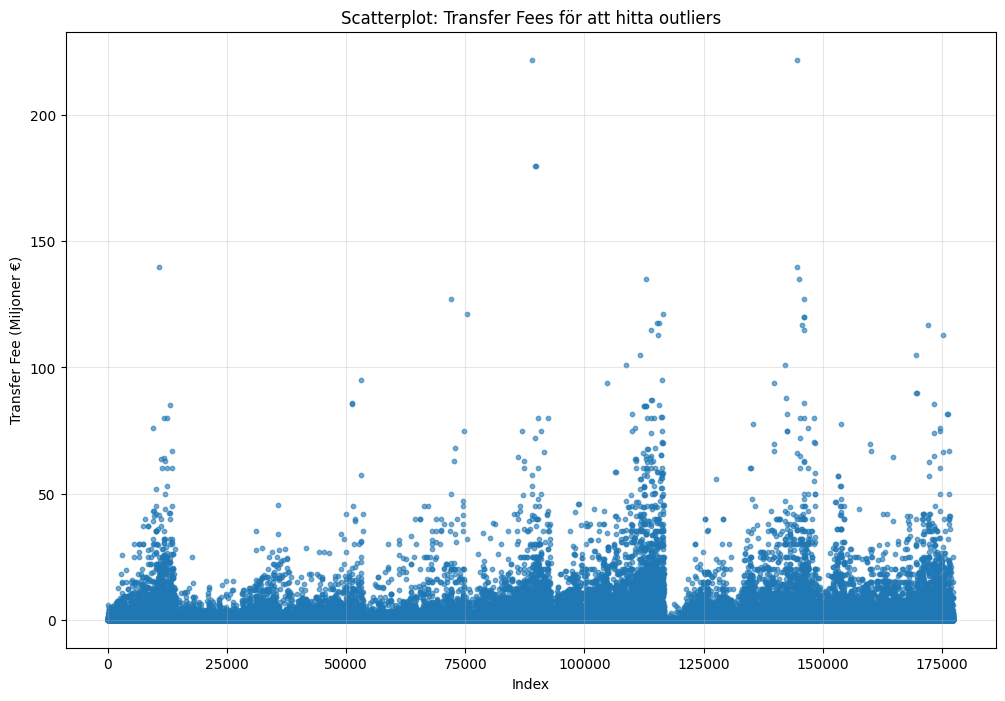

In [12]:
import matplotlib.pyplot as plt


fee_data = df_transfers.dropna(subset=['fee_cleaned'])


plt.figure(figsize=(12, 8))
plt.scatter(fee_data.index, fee_data['fee_cleaned'], alpha=0.6, s=10)
plt.xlabel('Index')
plt.ylabel('Transfer Fee (Miljoner €)')
plt.title('Scatterplot: Transfer Fees för att hitta outliers')
plt.grid(True, alpha=0.3)


threshold = fee_data['fee_cleaned'].quantile(0.95)
outliers = fee_data[fee_data['fee_cleaned'] > threshold]

print(f"Outlier threshold (95e percentilen): €{threshold:.2f}M")
print(f"Antal outliers: {len(outliers)}")
print(f"\nTopp 20 dyraste transfers:")
top_transfers = fee_data.nlargest(20, 'fee_cleaned')[['player_name', 'fee_cleaned', 'to_club', 'from_club', 'year']]
print(top_transfers)

plt.show()

In [13]:
# Ta bort dubbletter
original_length = len(df_transfers)
duplicates = df_transfers[df_transfers.duplicated(subset=['player_name', 'from_club', 'to_club', 'year'], keep=False)]
if len(duplicates) > 0:
    print("Exempel på dubbletter (sorterade för att se matchande par):")
    sample_duplicates = duplicates.sort_values(['player_name', 'from_club', 'to_club', 'year'])
    print(sample_duplicates[['player_name', 'from_club', 'to_club', 'year', 'league_name']].head(10))

df_transfers = df_transfers.drop_duplicates(subset=['player_name', 'fee_cleaned', 'year'])

print(f"\nOriginal antal transfers: {original_length}")
print(f"Efter borttagning av dubbletter: {len(df_transfers)}")
print(f"Antal borttagna dubbletter: {original_length - len(df_transfers)}")
print(f"Nytt dataset storlek: {len(df_transfers)}")


Exempel på dubbletter (sorterade för att se matchande par):
         player_name                from_club                  to_club  year  \
16227    Aaron Brown                 Tamworth               Reading FC  2005   
16230    Aaron Brown                 Tamworth               Reading FC  2005   
9545      Aaron Hunt            VfL Wolfsburg             Hamburger SV  2015   
9905      Aaron Hunt            VfL Wolfsburg             Hamburger SV  2015   
25656  Aaron McCarey                  Walsall  Wolverhampton Wanderers  2012   
25658  Aaron McCarey                  Walsall  Wolverhampton Wanderers  2012   
25668  Aaron McCarey  Wolverhampton Wanderers                  Walsall  2012   
25671  Aaron McCarey  Wolverhampton Wanderers                  Walsall  2012   
47287  Aaron Meijers             RKC Waalwijk             ADO Den Haag  2012   
47418  Aaron Meijers             RKC Waalwijk             ADO Den Haag  2012   

        league_name  
16227  Championship  
16230  Champion

Outlier threshold (95e percentilen): €8.80M
Antal outliers: 2500

Topp 20 dyraste transfers:
              player_name  fee_cleaned              to_club  \
89080              Neymar        222.0  Paris Saint-Germain   
89642       Kylian Mbappé        180.0             Paris SG   
10697     Ousmane Dembélé        140.0            Barcelona   
112946  Philippe Coutinho        135.0            Barcelona   
71956          João Félix        127.2      Atlético Madrid   
75241      Enzo Fernández        121.0              Chelsea   
146074  Antoine Griezmann        120.0         FC Barcelona   
115307      Jack Grealish        117.5             Man City   
145634  Cristiano Ronaldo        117.0             Juventus   
113934        Eden Hazard        115.0          Real Madrid   
115388      Romelu Lukaku        113.0           Chelsea FC   
111651         Paul Pogba        105.0    Manchester United   
108729        Gareth Bale        101.0          Real Madrid   
53045              Antony

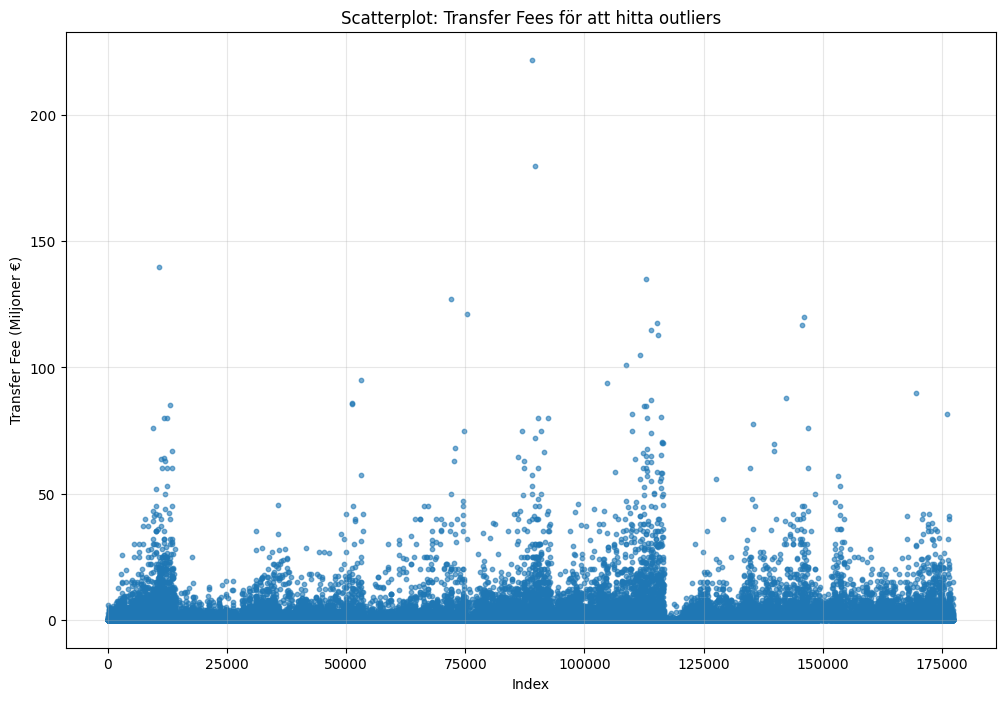

In [14]:
fee_data = df_transfers.dropna(subset=['fee_cleaned'])


plt.figure(figsize=(12, 8))
plt.scatter(fee_data.index, fee_data['fee_cleaned'], alpha=0.6, s=10)
plt.xlabel('Index')
plt.ylabel('Transfer Fee (Miljoner €)')
plt.title('Scatterplot: Transfer Fees för att hitta outliers')
plt.grid(True, alpha=0.3)


threshold = fee_data['fee_cleaned'].quantile(0.95)
outliers = fee_data[fee_data['fee_cleaned'] > threshold]

print(f"Outlier threshold (95e percentilen): €{threshold:.2f}M")
print(f"Antal outliers: {len(outliers)}")
print(f"\nTopp 20 dyraste transfers:")
top_transfers = fee_data.nlargest(20, 'fee_cleaned')[['player_name', 'fee_cleaned', 'to_club', 'from_club', 'year']]
print(top_transfers)

plt.show()

In [15]:
# Drop alla rader där fee_cleaned är NaN eller 0
original_length = len(df_transfers)
df_transfers = df_transfers.dropna(subset=['fee_cleaned'])
df_transfers = df_transfers[df_transfers['fee_cleaned'] > 0]

print(f"Original antal transfers: {original_length}")
print(f"Efter filtrering (ta bort NaN och 0): {len(df_transfers)}")
print(f"Antal borttagna transfers: {original_length - len(df_transfers)}")

Original antal transfers: 119584
Efter filtrering (ta bort NaN och 0): 22936
Antal borttagna transfers: 96648


Outlier threshold (95e percentilen): €15.42M
Antal outliers: 1147

Topp 20 dyraste transfers:
              player_name  fee_cleaned              to_club  \
89080              Neymar        222.0  Paris Saint-Germain   
89642       Kylian Mbappé        180.0             Paris SG   
10697     Ousmane Dembélé        140.0            Barcelona   
112946  Philippe Coutinho        135.0            Barcelona   
71956          João Félix        127.2      Atlético Madrid   
75241      Enzo Fernández        121.0              Chelsea   
146074  Antoine Griezmann        120.0         FC Barcelona   
115307      Jack Grealish        117.5             Man City   
145634  Cristiano Ronaldo        117.0             Juventus   
113934        Eden Hazard        115.0          Real Madrid   
115388      Romelu Lukaku        113.0           Chelsea FC   
111651         Paul Pogba        105.0    Manchester United   
108729        Gareth Bale        101.0          Real Madrid   
53045              Anton

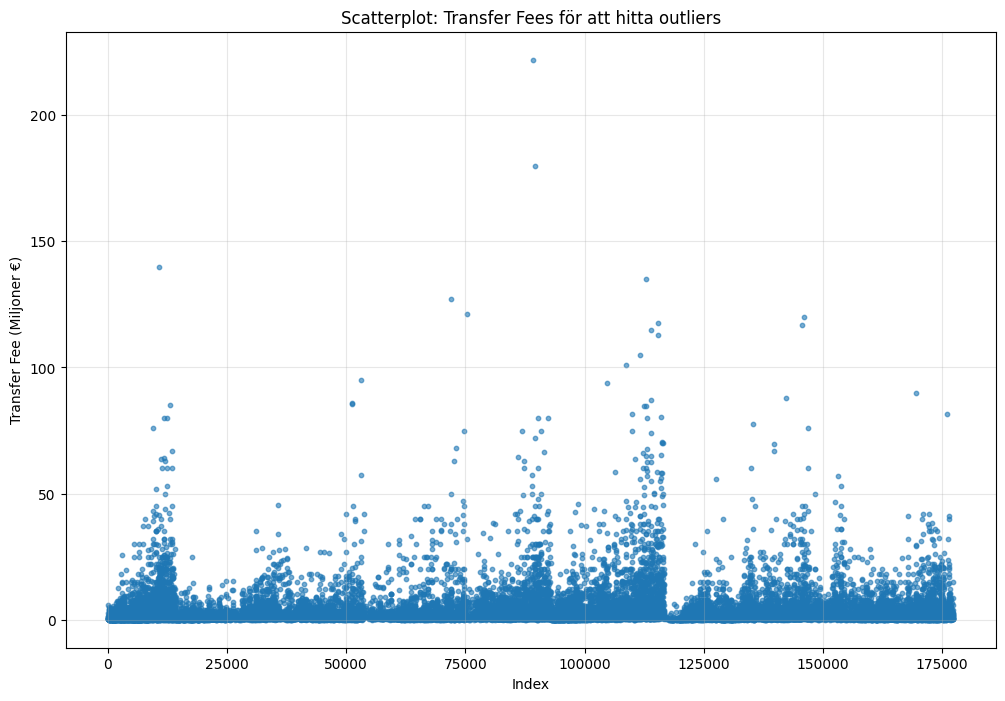

In [16]:
fee_data = df_transfers.dropna(subset=['fee_cleaned'])


plt.figure(figsize=(12, 8))
plt.scatter(fee_data.index, fee_data['fee_cleaned'], alpha=0.6, s=10)
plt.xlabel('Index')
plt.ylabel('Transfer Fee (Miljoner €)')
plt.title('Scatterplot: Transfer Fees för att hitta outliers')
plt.grid(True, alpha=0.3)


threshold = fee_data['fee_cleaned'].quantile(0.95)
outliers = fee_data[fee_data['fee_cleaned'] > threshold]

print(f"Outlier threshold (95e percentilen): €{threshold:.2f}M")
print(f"Antal outliers: {len(outliers)}")
print(f"\nTopp 20 dyraste transfers:")
top_transfers = fee_data.nlargest(20, 'fee_cleaned')[['player_name', 'fee_cleaned', 'to_club', 'from_club', 'year']]
print(top_transfers)

plt.show()

In [17]:
print(f"Antal transfers med fee_cleaned = 0: {(df_transfers['fee_cleaned'] == 0.0).sum()}")
print(f"Minsta fee_cleaned värde: {df_transfers['fee_cleaned'].min()}")

Antal transfers med fee_cleaned = 0: 0
Minsta fee_cleaned värde: 0.001


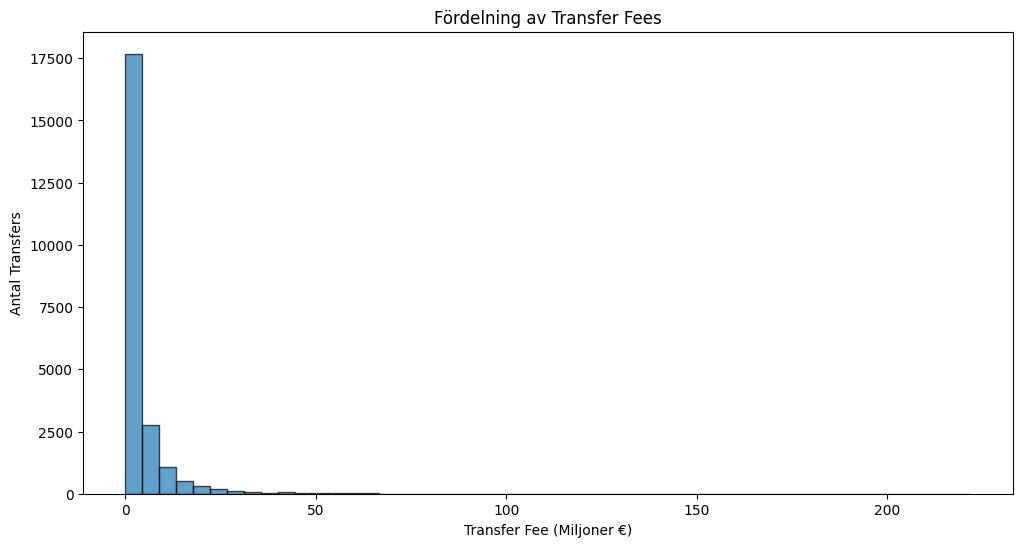

In [18]:
plt.figure(figsize=(12, 6))
plt.hist(df_transfers['fee_cleaned'], bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Transfer Fee (Miljoner €)')
plt.ylabel('Antal Transfers')
plt.title('Fördelning av Transfer Fees')
plt.show()

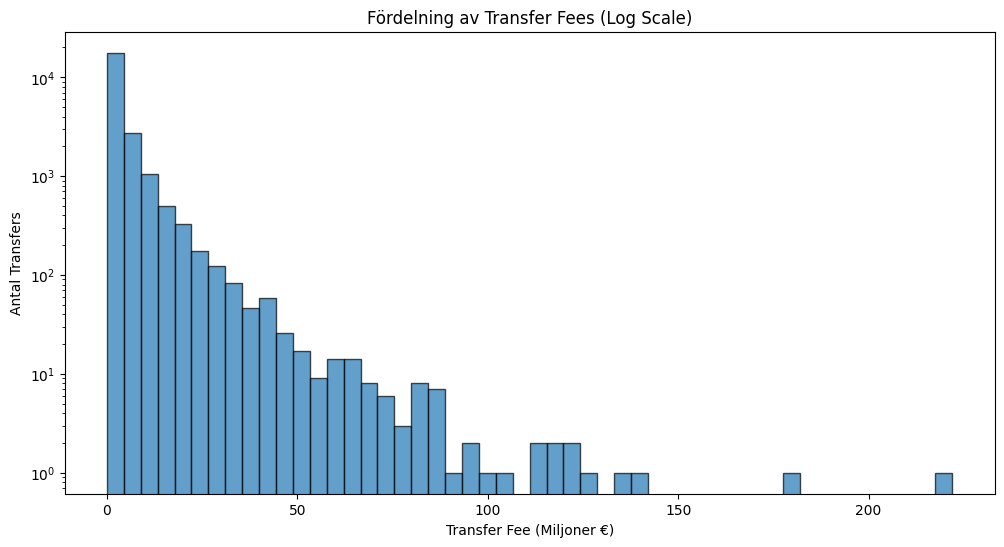

In [19]:
plt.figure(figsize=(12, 6))
plt.hist(df_transfers['fee_cleaned'], bins=50, edgecolor='black', alpha=0.7)
plt.xlabel('Transfer Fee (Miljoner €)')
plt.ylabel('Antal Transfers')
plt.title('Fördelning av Transfer Fees (Log Scale)')
plt.yscale('log') 
plt.show()

In [20]:
all_clubs = set(df_transfers['to_club'].unique()) | set(df_transfers['from_club'].unique())
print(f"Totalt antal unika klubbar: {len(all_clubs)}")
for club in sorted(all_clubs):
    print(club)

Totalt antal unika klubbar: 2163
1. FC Brno
1. FC Köln
1.FC Heidenheim
1.FC K'lautern
1.FC Kaiserslautern
1.FC Köln U19
1.FC Magdeburg
1.FC Nuremberg
1.FC Saarbrücken
1.FC Union Berlin
1.FSV Mainz 05
1.SC Feucht
1860 Munich
1º de Agosto
A. Klagenfurt
A. Malagueño
A.I.S.
AC Ajaccio
AC Arles
AC Bellinzona
AC Carpenedolo
AC Cesena
AC Fiorentina
AC Horsens
AC Le Havre
AC Merlan Lome
AC Milan
AC Montichiari
AC Monza
AC Parma
AC Perugia
AC Pisa
AC Reggiana
AC Siena
AC Venezia 1907
ACF Fiorentina
AD Limonense
ADO Den Haag
AE Larisa
AEK Athens
AFC Bournemouth
AFC Wimbledon
AGOVV
AIK
AJ Auxerre
AJ Auxerre U19
AO Egaleo
AO Kavala
APOEL Nicosia
AS Avellino
AS Bamako
AS Bari
AS Cannes
AS Cherbourg
AS Gubbio
AS Livorno
AS Monaco
AS Nancy
AS Nancy B
AS Nancy U19
AS Nancy-Lorraine
AS Pescina
AS Pizzighettone
AS Red Star 93
AS Roma
AS Saint-Étienne
AS Trencin
AS Vita Club
ASEC Mimosas
ASG Nocerina
ASO Chlef
AZ Alkmaar
AZ Alkmaar U21
Aalborg BK
Aalesund
Aarhus GF
Aberdeen FC
Ac. Chisinau
Académica Coim